# End-to-end text explainability on real backends

**Business context:** product and policy teams need to see which prompt words drive a model answer before shipping a refund assistant. This notebook explains one question with each built-in model backend.

**Goal:** explain the same snapshot with the `config/` presets: LM Studio, Hugging Face transformers (with the prefix KV cache, `backend.options.dtype` and a pinned `revision`) and the OpenAI-compatible HTTP API backend; check efficiency and render every result.

**Prerequisites:** a clone of the repository and `pip install "mllm-shap[transformers,api,viz]"`. LM Studio also needs `mllm-shap[lmstudio]` and a server with `qwen2-500m-instruct` loaded (`MLLM_SHAP_LMSTUDIO_MODEL`); without one, that section prints why it was skipped. Transformers downloads `HuggingFaceTB/SmolLM2-360M-Instruct` (about 720 MB; `MLLM_SHAP_E2E_MODEL`), small enough for a CPU. The API section runs offline against an in-process stand-in.

**Expected output:** per backend, efficient values, scheduler metrics and two charts; identical transformers values with the KV cache on and off.

In [1]:
import json
import os
import re
from pathlib import Path

import httpx
import matplotlib.pyplot as plt

from mllm_shap import (
    ApiBackend,
    BackendUnavailableError,
    CoalitionMask,
    ConversationSnapshot,
    DeletePolicy,
    ExplainConfig,
    ExplainRunner,
    ExplainRunOutput,
    Message,
    PluginContext,
    Role,
    TransformersTextBackend,
    Turn,
    explain_config_from_yaml,
    render_attribution,
)

# Quiet Hugging Face download progress bars and advisory warnings.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")

try:
    import lmstudio as lms
except ImportError:  # optional extra: mllm-shap[lmstudio]
    lms = None

## Shared scenario

**Technical:** A system message forbids invented policy details and counter-questions and stays in every coalition (`tokens` option `roles`); the user question has eight whitespace players. Each backend starts from its preset in `config/` (`dev_lmstudio.yaml`, `dev_transformers.yaml`, `dev_api.yaml`: exact Shapley, `tfidf_cosine`, the `pad` absence policy); `preset` replaces only the keys a section needs and re-validates the result. `report` prints the values next to the efficiency check.

In [2]:
SYSTEM = (
    "You are a support assistant for a store. Answer only from the question, in one "
    'short sentence. If it does not give enough information, say "Not enough '
    'information." Never invent policy details and never ask a question.'
)
PROMPT = "Can I refund within thirty days with receipt?"
LMSTUDIO_MODEL_ID = os.environ.get("MLLM_SHAP_LMSTUDIO_MODEL", "qwen2-500m-instruct")
DEFAULT_MODEL_ID = "HuggingFaceTB/SmolLM2-360M-Instruct"
TRANSFORMERS_MODEL_ID = os.environ.get("MLLM_SHAP_E2E_MODEL", DEFAULT_MODEL_ID)
# Commit of SmolLM2-360M-Instruct this notebook was run with.
DEFAULT_REVISION = "a10cc1512eabd3dde888204e902eca88bddb4951"
CONFIG_DIR = next(
    path / "config"
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "config" / "dev_transformers.yaml").is_file()
)
snapshot = ConversationSnapshot.from_turns((
    Turn(
        messages=(
            Message(role=Role.SYSTEM, text=SYSTEM),
            Message(role=Role.USER, text=PROMPT),
        )
    ),
))

In [3]:
def preset(
    name: str,
    backend: dict | None = None,
    explanation: dict | None = None,
    generation: dict | None = None,
) -> ExplainConfig:
    """Load ``config/<name>``, replace some keys and explain the user words only."""
    payload = explain_config_from_yaml((CONFIG_DIR / name).read_text()).model_dump(
        mode="json"
    )
    payload["backend"].update(backend or {})
    payload["generation"].update(generation or {})
    payload["explanation"].update(explanation or {})
    payload["explanation"]["plugin_options"] = {"tokens": {"roles": ["user"]}}
    return ExplainConfig.model_validate(payload)


def report(label: str, output: ExplainRunOutput) -> None:
    """Print the values per word and the efficiency check."""
    result = output.result
    print(label)
    for span, value in zip(output.player_set.spans, result.values, strict=True):
        print(f"  {span.text:>9} {value:+.4f}")
    print("  sum of values:", round(sum(result.values), 6))
    print("  grand - base: ", round(result.grand_value - result.base_value, 6))
    print(" ", output.metrics)

## LM Studio backend

**Business:** A local LM Studio server keeps prompts on the analyst's machine, which matters for confidential tickets.

**Technical:** The `lmstudio` backend talks to the LM Studio server through the `lmstudio` SDK; `dev_lmstudio.yaml` sets `backend.options.serialize_generate: true` so coalitions are generated one at a time. The cell looks for a running server first and prints why the section is skipped when the extra or the server is missing; the stored output below comes from the machine that last executed the notebook.

In [4]:
lmstudio_output = None
if lms is None:
    print(
        "Skipped: the lmstudio extra is not installed "
        "(pip install 'mllm-shap[lmstudio]')."
    )
else:
    host = await lms.AsyncClient.find_default_local_api_host()
    if host is None or not await lms.AsyncClient.is_valid_api_host(host):
        print(
            "Skipped: no LM Studio server found; "
            f"start it and load {LMSTUDIO_MODEL_ID}."
        )
    else:
        config = preset(
            "dev_lmstudio.yaml",
            backend={"model_id": LMSTUDIO_MODEL_ID, "api_host": host},
        )
        try:
            lmstudio_output = await ExplainRunner(config).explain(snapshot)
        except BackendUnavailableError as exc:
            print(f"Skipped: {exc}")
if lmstudio_output is not None:
    report("LM Studio", lmstudio_output)

LM Studio
        Can +0.2010
          I -0.0930
     refund +0.2083
     within +0.1595
     thirty +0.1487
       days +0.0292
       with +0.1333
   receipt? +0.1821
  sum of values: 0.96916
  grand - base:  0.96916
  SchedulerMetrics(requested=256, executed=255, deduplicated=0, cache_hits=1, kv_cache_hits=0, kv_cache_reused_tokens=0)


## Transformers backend

**Business:** An in-process model gives full control over weights and versions; pinning the Hub revision makes a rerun months later load the same weights.

**Technical:** `dev_transformers.yaml` enables `explanation.kv_cache`: every prompt shares a prefix with an earlier one, and the backend reuses the cached key/value states of the longest cached prefix instead of recomputing them (`kv_cache_hits` and `kv_cache_reused_tokens` count the reuse). `backend.options.revision` pins the Hub commit; `backend.options.dtype` (`auto`, `float32`, `float16`, `bfloat16`) picks the weight type, and `float32` here keeps the greedy answers identical on CPU, CUDA and Apple MPS (`auto` would pick bfloat16 on accelerators that support it). The second run switches the cache off: greedy outputs do not depend on it, so the values must match exactly.

In [5]:
transformers_options = {"dtype": "float32"}
if TRANSFORMERS_MODEL_ID == DEFAULT_MODEL_ID:
    transformers_options["revision"] = DEFAULT_REVISION
transformers_output = None
try:
    transformers_config = preset(
        "dev_transformers.yaml",
        backend={"model_id": TRANSFORMERS_MODEL_ID, "options": transformers_options},
        generation={"max_new_tokens": 24},
    )
    transformers_backend = TransformersTextBackend(
        PluginContext(config=transformers_config)
    )
    transformers_output = await ExplainRunner(
        transformers_config, backend=transformers_backend
    ).explain(snapshot)
    no_cache_output = await ExplainRunner(
        preset(
            "dev_transformers.yaml",
            backend={
                "model_id": TRANSFORMERS_MODEL_ID,
                "options": transformers_options,
            },
            generation={"max_new_tokens": 24},
            explanation={"kv_cache": {"enabled": False}},
        )
    ).explain(snapshot)
except (BackendUnavailableError, ImportError) as exc:
    print(f"Skipped: {exc}")
if transformers_output is not None:
    report("Transformers (KV cache on)", transformers_output)
    print("KV cache off:", no_cache_output.metrics)
    print(
        "identical values with and without the cache:",
        no_cache_output.result.values == transformers_output.result.values,
    )

Transformers (KV cache on)
        Can +0.0305
          I +0.2177
     refund +0.2703
     within +0.2619
     thirty +0.0264
       days +0.0630
       with +0.1128
   receipt? +0.0175
  sum of values: 1.0
  grand - base:  1.0
  SchedulerMetrics(requested=256, executed=255, deduplicated=0, cache_hits=1, kv_cache_hits=254, kv_cache_reused_tokens=16227)
KV cache off: SchedulerMetrics(requested=256, executed=255, deduplicated=0, cache_hits=1, kv_cache_hits=0, kv_cache_reused_tokens=0)
identical values with and without the cache: True


**What the model answers.** Each value summarises answers like these: the full question, then the question with one word deleted. A word matters when its absence changes the answer.

In [6]:
if transformers_output is not None:
    players = transformers_output.player_set
    generation = transformers_config.generation
    full = await transformers_backend.generate(snapshot, generation)
    print(f"{'full question':>18} -> {full.text!r}")
    for index, span in enumerate(players.spans):
        mask = CoalitionMask.from_sequence(
            tuple(other != index for other in range(players.num_players))
        )
        absent = DeletePolicy().apply(snapshot, players, mask)
        answer = await transformers_backend.generate(absent, generation)
        print(f"{'without ' + span.text:>18} -> {answer.text!r}")

     full question -> 'Yes, you can refund within thirty days with a receipt.'


       without Can -> 'Yes, I can refund within thirty days with a receipt.'


         without I -> 'Yes, refunds can be made within thirty days with a receipt.'


    without refund -> 'Yes, you can within thirty days with receipt.'


    without within -> 'Yes, you can return the product within thirty days of purchase with a receipt.'


    without thirty -> 'Yes, you can refund within days with a receipt.'


      without days -> 'Yes, you can refund within thirty days with a receipt.'


      without with -> 'Yes, you can refund within thirty days receipt.'


  without receipt? -> 'Yes, you can refund within thirty days.'


SmolLM2 answers the question; masking `refund` or `within` (and the pronoun `I`) changes that answer most. A 360M model is a weak judge, so read the ranking as a demonstration. The values add up to `grand_value - base_value`, the grand coalition reuses the base generation (the one cache hit), and almost every coalition reuses a cached prefix.

## OpenAI-compatible HTTP API backend

**Business:** hosted models (OpenAI, vLLM, LM Studio in server mode) speak the same chat-completions protocol; retries and timeouts decide whether a long run survives a flaky network.

**Technical:** the `api` backend posts each coalition to `<api_host>/chat/completions` and retries transient failures (status codes, backoff and API keys: [backends guide](https://pawlo77.github.io/MLLM-SHAP/guides/backends.html)). Here an `httpx.MockTransport` plays the server: it fails the first request with 503, then answers from keywords like the stand-in of `explain_pipeline.ipynb`. `async with` closes the injected backend; for a real server, drop `transport=` and point `api_host` at it.

In [7]:
requests_seen = []


def openai_stand_in(request: httpx.Request) -> httpx.Response:
    """Answer chat completions from keywords; fail the first request with 503."""
    requests_seen.append(request)
    if len(requests_seen) == 1:
        return httpx.Response(503, headers={"Retry-After": "0"})
    prompt = json.loads(request.content)["messages"][-1]["content"]
    words = set(re.findall(r"[a-z]+", prompt.lower()))
    phrases = [
        p
        for k, p in (("refund", "refund approved"), ("receipt", "receipt checked"))
        if k in words
    ]
    reply = " ".join(phrases) or "please clarify"
    return httpx.Response(
        200, json={"choices": [{"message": {"role": "assistant", "content": reply}}]}
    )


api_config = preset(
    "dev_api.yaml", backend={"api_host": "http://stand-in.local/v1", "max_retries": 1}
)
api_backend = ApiBackend(
    PluginContext(config=api_config), transport=httpx.MockTransport(openai_stand_in)
)
async with ExplainRunner(api_config, backend=api_backend) as api_runner:
    api_output = await api_runner.explain(snapshot)
print("HTTP requests:", len(requests_seen), "(one retried after the 503)")
report("HTTP API", api_output)

HTTP requests: 257 (one retried after the 503)
HTTP API
        Can +0.0000
          I +0.0000
     refund +0.5000
     within +0.0000
     thirty +0.0000
       days +0.0000
       with +0.0000
   receipt? +0.5000
  sum of values: 1.0
  grand - base:  1.0
  SchedulerMetrics(requested=256, executed=255, deduplicated=0, cache_hits=1, kv_cache_hits=0, kv_cache_reused_tokens=0)


The stand-in only reacts to `refund` and `receipt?`, so the two words share the value equally and the other six get 0. Every coalition is a distinct prompt, so the backend sent one request per executed coalition (the grand coalition reuses the base answer) plus two for the base generation: the 503 and its retry.

## Visual comparison

**Technical:** `render_attribution` draws the result with a renderer plugin (`token_text` colours the words, `token_bar` sorts them by impact); `output.player_set` holds the players the run explained.

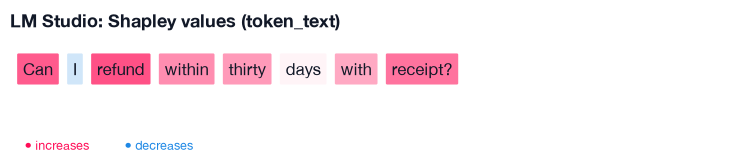

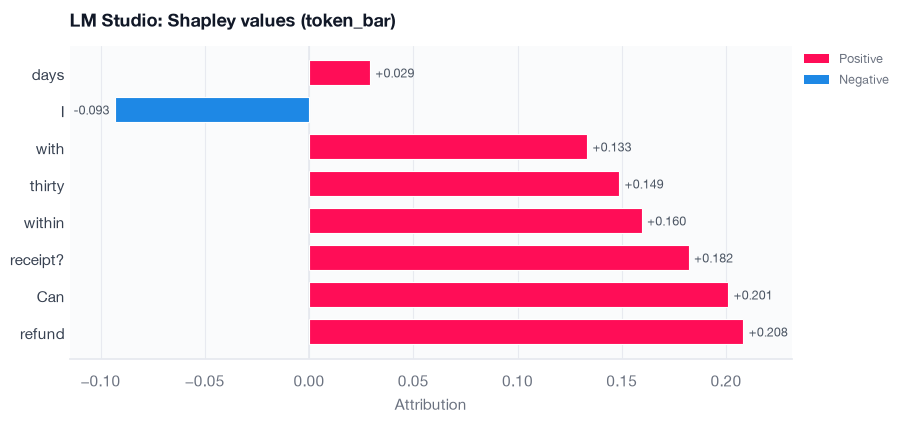

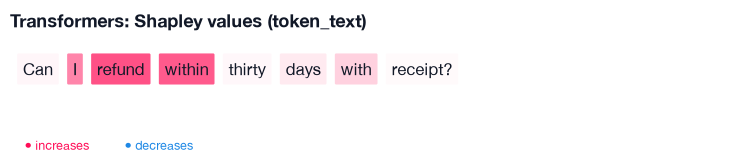

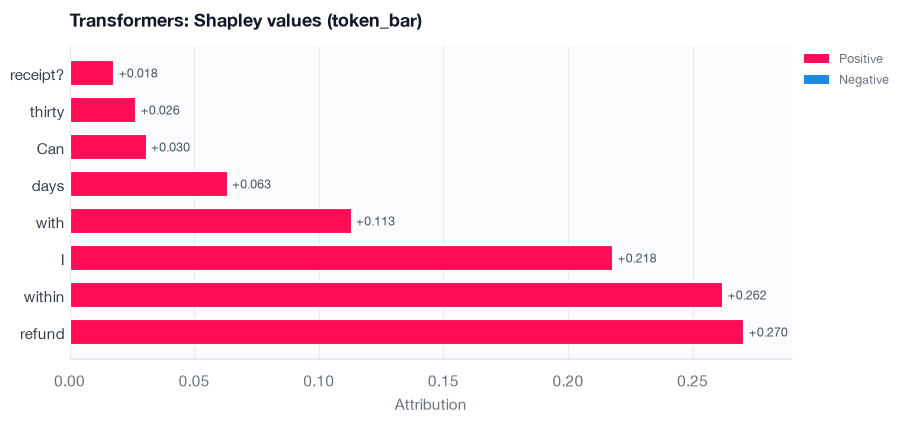

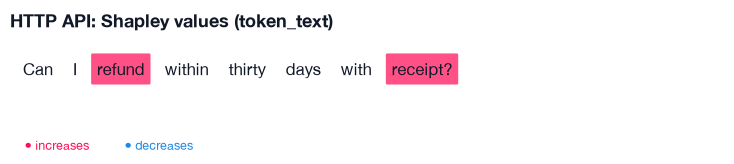

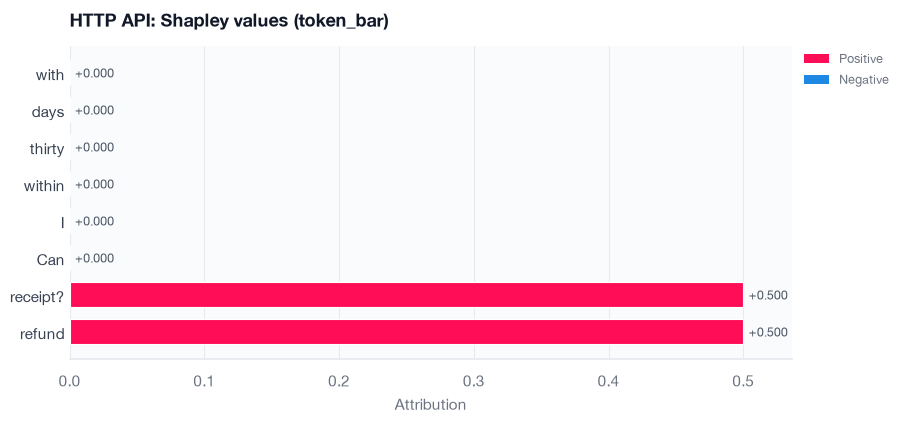

In [8]:
for label, output in (
    ("LM Studio", lmstudio_output),
    ("Transformers", transformers_output),
    ("HTTP API", api_output),
):
    if output is None:
        print(f"{label}: skipped above, nothing to draw.")
        continue
    for renderer in ("token_text", "token_bar"):
        render_attribution(
            output,
            snapshot,
            output.player_set,
            renderer=renderer,
            title=f"{label}: Shapley values ({renderer})",
        )
        plt.show()